<a href="https://colab.research.google.com/github/infinityrohit07/tensorflow-learning/blob/main/notebooks/12_building_and_training_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Building and Training Your First Neural Network**

<br>

#### 1. **Understanding the Problem**

Before building a neural network, we need to understand the problem and prepare our data.

We worked with a simple regression problem.

Our dataset:

In [1]:
import tensorflow as tf

X = tf.constant([1, 2, 3, 4, 5], dtype=tf.float32)

y = tf.constant([20, 30, 40, 50, 60], dtype=tf.float32)

Here:

- `X` represents input features.
- `y` represents actual target values (labels).

<br>

Our dataset follows this relationship:

$$
y = 10x + 10
$$

For example:

- If x = 1, y = 20.
- If x = 2, y = 30.
- If x = 3, y = 40.

**Our goal:** Train a neural network to learn this relationship so that it can predict the correct output for new inputs.

<br>

#### 2. **Building a Neural Network Using Sequential**

We use `tf.keras.Sequential` to create a neural network by stacking layers in sequence.

Example:

In [2]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(1)
])

**`tf.keras.Sequential`**

- Creates a neural network by stacking layers one after another.
- Data flows through the layers in sequence.

**`tf.keras.Input(shape=(1,))`**

- Specifies the shape of the input data.
- `1` means each sample contains one input feature.
- The batch dimension is handled automatically.

**`tf.keras.layers.Dense(1)`**

- Creates a fully connected (Dense) layer.
- `1` means the layer contains one neuron.
- Each neuron has weights and a bias.

#### **What is a Dense Layer?**

A Dense layer is a fully connected layer in which every neuron receives input from all the outputs of the previous layer.

The mathematical formula for a neuron is:

$$
z = wx+b
$$

Where:

- $(x)$ = Input
- $(w)$ = Weight
- $(b)$ = Bias
- $(z)$ = Output before activation

<br>

For a simple Dense layer with one input feature and one neuron:

$$
\text{Parameters} = (1 \times 1)+1 = 2
$$

<br>

These two trainable parameters are one weight and one bias.

<br>

#### 3. **Understanding the Model Summary**

In [3]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

This displays information such as:

- Layer names and types.
- Output shapes.
- Number of trainable parameters.

For our model, the output shape is `(None, 1)`.

Here:

- `None` represents a variable batch size.
- `1` represents one output value per sample.


<br>

#### 4. **Compiling the Model**

Before training, we need to compile the model.

Compilation configures the optimizer, loss function, and evaluation metrics.

Example:

In [5]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)


**1. Optimizer**

The optimizer updates the model's weights and biases to reduce the loss.

We used Adam:

```python
tf.keras.optimizers.Adam(learning_rate=0.001)
```

- Adam is an optimization algorithm.
- It adjusts the model's parameters using gradients.
- The learning rate controls the step size of parameter updates.

<br>

**2. Loss Function**

The loss function measures how far the model's predictions are from the actual values.

We used Mean Squared Error (MSE):

```python
loss="mean_squared_error"
```

The optimizer tries to minimize this loss during training.

<br>

**3. Metrics**

Metrics help us monitor the model's performance.

We used Mean Absolute Error (MAE):

```python
metrics=["mean_absolute_error"]
```

MAE tells us the average absolute difference between actual and predicted values.

<br>

**Important distinction:**

- Loss is used by the optimizer to guide training.
- Metrics help us understand model performance.


<br>

#### 5. **Training the Model Using model.fit()**

After compiling the model, we train it using `model.fit()`.

Example:

In [6]:
history = model.fit(X, y, epochs=100)


Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step - loss: 2093.3066 - mean_absolute_error: 43.0229
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2092.9185 - mean_absolute_error: 43.0189
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 2092.5305 - mean_absolute_error: 43.0149
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 2092.1421 - mean_absolute_error: 43.0109
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 2091.7544 - mean_absolute_error: 43.0069
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 2091.3660 - mean_absolute_error: 43.0029
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2090.9783 - mean_absolute_error: 42.9989
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 2090.5901 - mean_absolute_error: 42.9949
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2090.2021 - mean_absolute_error: 42.9909
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 2089.8145 - mean_absolute_error: 42.9869
Epoch 11

Understanding the arguments

- `X`: Input features.
- `y`: Actual target values.
- `epochs=100`: The model goes through the entire training dataset 100 times.

<br>

**What happens during training?**

During training:

1. The model receives input data.
2. It performs forward propagation to generate predictions.
3. The loss function calculates the prediction error.
4. Backpropagation calculates gradients.
5. The optimizer updates weights and biases to reduce the loss.

This process repeats throughout the training epochs.

<br>

**What is an Epoch?**

An epoch is one complete pass through the entire training dataset.

For example:

If we have 100 training samples and train for 10 epochs, the model processes the complete dataset 10 times.

**Important:** An epoch does not necessarily mean one weight update.

The number of updates depends on the batch size.

<br>

**What is a Batch?**

A batch is a group of training samples processed together before an optimizer update.

For example:

- Dataset size = 1,000 samples.
- Batch size = 100.
- Number of batches per epoch = 10.
- Optimizer updates per epoch = 10.

When training directly with arrays or tensors, Keras commonly uses a default batch size of 32 if we don't specify one.


<br>

#### 6. **Understanding Training Results**

The `model.fit()` method returns a History object.

```python
history = model.fit(X, y, epochs=100)
```

We can inspect the recorded training loss:
```python
history.history
```


In [10]:
print(history.history["loss"])

# This gives us the loss values recorded after each epoch.

# We can also access MAE:

print(history.history["mean_absolute_error"])

[2093.306640625, 2092.91845703125, 2092.530517578125, 2092.14208984375, 2091.75439453125, 2091.365966796875, 2090.978271484375, 2090.590087890625, 2090.2021484375, 2089.814453125, 2089.42626953125, 2089.03857421875, 2088.65087890625, 2088.26318359375, 2087.87548828125, 2087.488037109375, 2087.10009765625, 2086.712890625, 2086.325439453125, 2085.93798828125, 2085.55078125, 2085.1630859375, 2084.77587890625, 2084.388671875, 2084.00146484375, 2083.614501953125, 2083.22705078125, 2082.840087890625, 2082.453125, 2082.066162109375, 2081.67919921875, 2081.29248046875, 2080.90576171875, 2080.518798828125, 2080.13232421875, 2079.74560546875, 2079.35888671875, 2078.97216796875, 2078.5859375, 2078.199462890625, 2077.81298828125, 2077.4267578125, 2077.040283203125, 2076.654296875, 2076.26806640625, 2075.882080078125, 2075.49560546875, 2075.10986328125, 2074.72412109375, 2074.337890625, 2073.951904296875, 2073.56591796875, 2073.18017578125, 2072.79443359375, 2072.408935546875, 2072.0234375, 2071.63

Why do we monitor loss?

- Decreasing loss generally indicates that the model is learning.
- High loss indicates that predictions are still far from actual values.
- Loss that stops improving may indicate that training needs adjustment.


<br>

#### 7. **Making Predictions Using model.predict()**

After training, we can use the model to predict outputs for new inputs.

Example:

In [11]:
X_new = tf.constant([6, 7, 8], dtype=tf.float32)

predictions = model.predict(X_new)

print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
[[-5.3469205]
 [-6.2547145]
 [-7.162508 ]]


Our actual relationship is:

$$
y = 10x+10
$$

Therefore, the expected outputs are:

| Input | Expected Output |
|---:|---:|
| 6 | 70 |
| 7 | 80 |
| 8 | 90 |

so we know we didn't get the expected output.


<br>

#### 8. **Evaluating the Model Using model.evaluate()**

Prediction tells us what the model outputs.

Evaluation helps us measure how well the model performs on a given dataset.

Example:

In [12]:
model.evaluate(X, y)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - loss: 2054.7261 - mean_absolute_error: 42.6235


[2054.72607421875, 42.62353515625]

This returns the loss and the metrics configured during compilation.

For our model:

- Loss = MSE.
- Metric = MAE.

<br>

We can also evaluate using separate test data:

```python
model.evaluate(X_test, y_test)
```

This helps measure how well the trained model generalizes to unseen data.


<br>

#### 9. **Improving Model Performance**

During our first experiment, we used:

```python
optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
```

We observed that the loss was decreasing very slowly and the predictions were not close to the expected values.

#### **Creating a Second Model**

In [13]:
model_2 = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(1)
])

model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

In [14]:
history_2 = model_2.fit(X, y, epochs=100)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 540ms/step - loss: 1401.4138 - mean_absolute_error: 35.4595
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 1369.8320 - mean_absolute_error: 35.0595
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1338.6199 - mean_absolute_error: 34.6596
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1307.7834 - mean_absolute_error: 34.2599
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1277.3291 - mean_absolute_error: 33.8606
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 1247.2623 - mean_absolute_error: 33.4616
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 1217.5885 - mean_absolute_error: 33.0631
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 1188.3131 - mean_absolute_error: 32.6651
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1159.4407 - mean_absolute_error: 32.2678
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 1130.9761 - mean_absolute_error: 31.8713
Epoch 11

the loss are still high.

#### **Continuing Training**

We then continued training the second model for additional epochs:

In [15]:
history_3 = model_2.fit(X, y, epochs=200)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 37.4731 - mean_absolute_error: 5.9178
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 35.5990 - mean_absolute_error: 5.7711
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 33.8075 - mean_absolute_error: 5.6271
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 32.0955 - mean_absolute_error: 5.4859
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 30.4600 - mean_absolute_error: 5.3475
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 28.8984 - mean_absolute_error: 5.2117
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 27.4077 - mean_absolute_error: 5.0786
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 25.9853 - mean_absolute_error: 4.9481
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 24.6285 - mean_absolute_error: 4.8203
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 23.3348 - mean_absolute_error: 4.6951
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

the loss is way too low with this training let predict and see if it produces correct output.

In [17]:
X_new = tf.constant([6, 7, 8], dtype=tf.float32)

predictions = model_2.predict(X_new)

print(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
[[70.68138]
 [80.95381]
 [91.22626]]


Based on the relationship, the expected outputs were:

| Input | Expected Output |
|---:|---:|
| 6 | 70 |
| 7 | 80 |
| 8 | 90 |

so we know we are close to our expected output and its good fit.

#### 10. **Visualizing Training Loss**

We can use Matplotlib to visualize how loss changes across epochs.

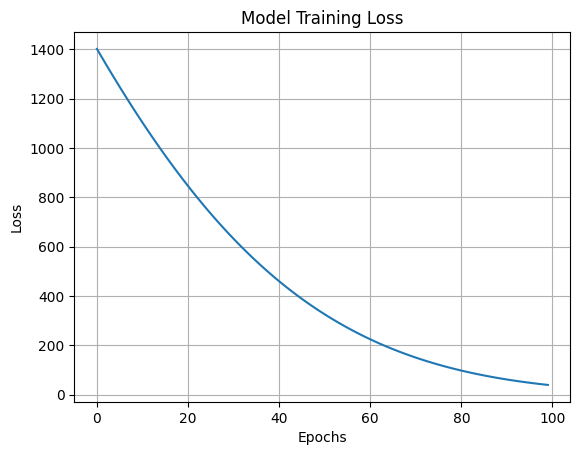

In [18]:
import matplotlib.pyplot as plt

loss = history_2.history["loss"]

plt.plot(loss)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Model Training Loss")

plt.grid()
plt.show()

A decreasing loss curve generally indicates that the model is learning from the training data.

Visualizing loss helps us understand training progress and identify possible problems.